# Resampling Dataset (Undersampling & SMOTE Oversampling)
Notebook ini menyeimbangkan distribusi target `NM_UNIT` menggunakan kombinasi Random Undersampling pada kelas mayoritas dan SMOTE pada kelas minoritas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

## 1. Load Data Imputasi

In [2]:
df = pd.read_csv('merge_DocLab_WithLab_imputed.csv')
print('Dimensi data awal:', df.shape)
print('\nDistribusi awal target:')
print(df['NM_UNIT'].value_counts().sort_index())

X = df.drop(columns=['NM_UNIT'])
y = df['NM_UNIT'].astype(int)

Dimensi data awal: (4160, 14)

Distribusi awal target:
NM_UNIT
0.0    3539
1.0      52
2.0     559
3.0      10
Name: count, dtype: int64


## 2. Undersampling Kelas Mayoritas (Kelas 0 & Kelas 2)

In [3]:
# Reduksi kelas 0 (kontrol) ke 1000 sampel dan kelas 2 (penyakit dalam) ke 500 sampel
undersampler = RandomUnderSampler(sampling_strategy={0: 1000, 2: 500}, random_state=42)
X_under, y_under = undersampler.fit_resample(X, y)

print('Distribusi setelah Undersampling (Kelas 0 -> 1000, Kelas 2 -> 500):')
print(y_under.value_counts().sort_index())

Distribusi setelah Undersampling (Kelas 0 -> 1000, Kelas 2 -> 500):
NM_UNIT
0    1000
1      52
2     500
3      10
Name: count, dtype: int64


## 3. SMOTE Oversampling Kelas Minoritas (Kelas 1 & 3)

In [4]:
# Naikkan kelas 1 (Jantung) dan kelas 3 (Paru) menjadi 500 sampel
# Menggunakan k_neighbors=3 karena sampel asli kelas 3 berjumlah 10
smote = SMOTE(sampling_strategy={1: 500, 3: 500}, k_neighbors=3, random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_under, y_under)

print('Distribusi akhir setelah SMOTE:')
print(y_resampled.value_counts().sort_index())

Distribusi akhir setelah SMOTE:
NM_UNIT
0    1000
1     500
2     500
3     500
Name: count, dtype: int64


## 4. Perapihan Format & Pembulatan Nilai

In [5]:
df_resampled = pd.DataFrame(X_resampled, columns=X.columns)
df_resampled['NM_UNIT'] = y_resampled.values

# Pastikan jenis kelamin dan umur tetap bulat
df_resampled['JENIS_KELAMIN'] = df_resampled['JENIS_KELAMIN'].round(0).astype(int)
df_resampled['UMUR_TAHUN'] = df_resampled['UMUR_TAHUN'].round(0)

# Pembulatan fitur lab ke 1 angka di belakang koma
lab_features = [col for col in df_resampled.columns if col not in ['JENIS_KELAMIN', 'UMUR_TAHUN', 'NM_UNIT']]
df_resampled[lab_features] = df_resampled[lab_features].round(1)

df_resampled.head()

,JENIS_KELAMIN,UMUR_TAHUN,cholesterol total,creatinin,fbs,rbs,hgb,lymfosit%,mch,mchc,mcv,ureum,wbc,NM_UNIT
0,2,0.0,198.8,7.1,101.0,121.0,8.5,15.8,26.7,32.6,82.1,83.0,5.3,0
1,2,0.0,194.5,0.8,109.4,136.6,13.2,31.3,28.5,33.2,85.7,36.6,6.7,0
2,2,0.0,189.8,1.5,115.8,135.8,11.8,16.0,28.5,33.4,85.2,37.6,11.8,0
3,2,0.0,191.5,0.8,109.4,136.2,13.8,29.4,24.2,31.2,77.7,35.2,6.7,0
4,2,0.0,192.4,5.1,125.4,272.0,11.9,20.1,25.4,31.7,81.0,126.0,8.7,0


## 5. Visualisasi & Simpan Dataset

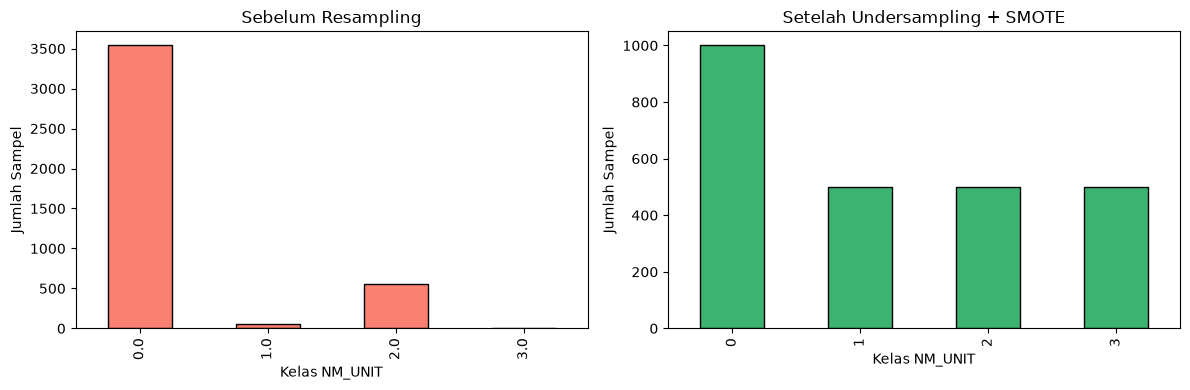

Dataset seimbang berhasil disimpan ke merge_DocLab_SMOTE.csv
Total baris: 2500
Distribusi akhir:
 NM_UNIT
0    1000
1     500
2     500
3     500
Name: count, dtype: int64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['NM_UNIT'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color='salmon', edgecolor='black'
)
axes[0].set_title('Sebelum Resampling')
axes[0].set_xlabel('Kelas NM_UNIT')
axes[0].set_ylabel('Jumlah Sampel')

df_resampled['NM_UNIT'].value_counts().sort_index().plot(
    kind='bar', ax=axes[1], color='mediumseagreen', edgecolor='black'
)
axes[1].set_title('Setelah Undersampling + SMOTE')
axes[1].set_xlabel('Kelas NM_UNIT')
axes[1].set_ylabel('Jumlah Sampel')

plt.tight_layout()
plt.show()

output_file = 'merge_DocLab_SMOTE.csv'
df_resampled.to_csv(output_file, index=False)
print(f'Dataset seimbang berhasil disimpan ke {output_file}')
print('Total baris:', len(df_resampled))
print('Distribusi akhir:\n', df_resampled['NM_UNIT'].value_counts().sort_index())